In [1]:

import h5py
import numpy as np
from utils import save, load
from library import *
import gc
from continuous_process_library_terms import *
from commons_identify_models import *
import copy
import jax
import jax.numpy as jnp
from jax_cfd.base import boundaries, grids, pressure, finite_differences as fd
import jax_cfd.base as cfd
import jax_cfd.base.grids as grids
import jax_cfd.spectral as spectral
import numpy as np
#import xarray 
#import xarray as xr
import dataclasses
import time
jax.config.update("jax_enable_x64", True)


In [2]:

f = h5py.File('/storage/scratch1/2/ashelestov3/snaps_paper/snaps_paper_s1.h5', 'r')
# '/storage/scratch1/2/ashelestov3/snaps_1024_1e8/snaps_1024_1e8_s1.h5'
# '/storage/scratch1/2/ashelestov3/snaps_2048_1e8/snaps_2048_1e8_s1.h5'
print(list(f['tasks'].keys()))
'''
f['tasks']['buoyancy'] = f['buoyancy'][901:]
f['tasks']['pressure'] = f['pressure'][901:]
f['tasks']['velocity'] = f['velocity'][901:]
f['tasks']['vorticity'] = f['vorticity'][901:]
'''
#print(f.type)

scales = f['scales']


f = f['tasks']
list(f.keys())



velocity = f['velocity']
vorticity = f['vorticity']
print(velocity.shape)
pressure_import = f['pressure']
buoyancy = f['buoyancy']
print(velocity)
print(velocity.shape)

del(f)

['buoyancy', 'pressure', 'velocity', 'vorticity']
(101, 2, 4096, 1536)
<HDF5 dataset "velocity": shape (101, 2, 4096, 1536), type "<f8">
(101, 2, 4096, 1536)


In [3]:
size_x = 4096
size_y = 1536
inner_steps = 1
outer_steps = 286

Lx =  4
Ly = 1
# Define the physical dimensions of the simulation.
Nx = size_x
Ny = size_y
Nt = outer_steps
dx = Lx/(size_x-1)
dy = Ly/(size_y-1)
print(dx)
print(Ly/(size_y-1))
Lt = 1.99

dt = 200/286*1e-3
print(dt)

Rayleigh = 1e8
Prandtl = 1
kappa = (Rayleigh * Prandtl)**(-1/2)
kappa

0.0009768009768009768
0.0006514657980456026
0.0006993006993006993


0.0001

In [4]:
print(-1)
P = np.array(pressure_import)
del(pressure_import)
B = np.array(buoyancy)
del(buoyancy)
vel = np.array(velocity)
del(velocity)
print("0")
u_trajectory = vel[:,0,:,:] #128:384
v_trajectory = vel[:,1,:,:]
del(vel)
P = P[:,:,:]
B = B[:,:,:]
print("1")
U = np.transpose(u_trajectory, (1,2,0))
del(u_trajectory)
V = np.transpose(v_trajectory, (1,2,0))
del(v_trajectory)
P = np.transpose(P, (1,2,0))
B = np.transpose(B, (1,2,0))
W = np.transpose(np.array(vorticity), (1,2,0))
del(vorticity)
print("2")
temp = U
U = V
V = temp

del(temp)

#for 1024: x_hash_89db91f00173784cfec0de1995a005933e22284d
#for 2048: x_hash_01660bd46ab85b39c93c0a1ba2065afc4fa8e0ae
#for 4096: x_hash_4846e26f3f50e48ca5da4b8e0970d850261c704a  
#h       : x_hash_4846e26f3f50e48ca5da4b8e0970d850261c704a
x = scales['x_hash_4846e26f3f50e48ca5da4b8e0970d850261c704a'][:]#['1.0'][:]    # If your x-basis is named 'x'
#for 1024: z_hash_3c859c36a9c2f295aaab1dec0ec24d51221a3714  
#for 2048: z_hash_ca4c26aa6571658dd2ab8a9fb304c058f0ca9e5c
#for 4096: z_hash_050b2c5be05fb65046d37e4f71ee7ab1962cccdc  
y = scales['z_hash_050b2c5be05fb65046d37e4f71ee7ab1962cccdc'][:]#['1.0'][:]    # Likewise for y
t = scales['sim_time'][:]#['1.0'][:]del(temp)del(temp)del(temp)
del(scales)

-1
0
1
2


In [5]:
#INTERPOLATION
from scipy.interpolate import BarycentricInterpolator

print(x.shape, y.shape)
print(np.all(np.diff(y) > 0))
ys = np.linspace(0, 1, 1536) #scale for resolution
u_lin = BarycentricInterpolator(y, U, axis=1)(ys)
print("U_succ")
v_lin = BarycentricInterpolator(y, V, axis=1)(ys)
b_lin = BarycentricInterpolator(y, B, axis=1)(ys)
p_lin = BarycentricInterpolator(y, P, axis=1)(ys)
w_lin = BarycentricInterpolator(y, W, axis=1)(ys)
print(v_lin)
print(w_lin)

(4096,) (1536,)
True
U_succ
[[[-0.8319649  -0.83196093 -0.83195696 ... -0.83157681 -0.83157287
   -0.83156892]
  [-0.83192602 -0.83192206 -0.83191809 ... -0.83153837 -0.83153442
   -0.83153048]
  [-0.83180997 -0.83180602 -0.83180207 ... -0.83142358 -0.83141965
   -0.83141572]
  ...
  [ 0.24892133  0.24893383  0.24894633 ...  0.25014167  0.25015408
    0.25016648]
  [ 0.24883128  0.2488438   0.24885631 ...  0.25005297  0.25006538
    0.2500778 ]
  [ 0.24880126  0.24881378  0.2488263  ...  0.25002339  0.25003581
    0.25004823]]

 [[-0.83193737 -0.83193339 -0.83192941 ... -0.83154868 -0.83154473
   -0.83154078]
  [-0.83189858 -0.8318946  -0.83189062 ... -0.8315103  -0.83150636
   -0.83150241]
  [-0.83178275 -0.83177878 -0.83177482 ... -0.83139573 -0.8313918
   -0.83138787]
  ...
  [ 0.24657177  0.2465844   0.24659704 ...  0.24780515  0.24781768
    0.24783022]
  [ 0.24648007  0.24649272  0.24650536 ...  0.24771481  0.24772736
    0.24773991]
  [ 0.24644949  0.24646215  0.2464748  ...  0.

In [6]:
print(ys[1]-ys[0])
print(dy)
dy=ys[1]-ys[0]
print(w_lin)

0.0006514657980456026
0.0006514657980456026
[[[-5.67791613e-10  4.42337873e-09  2.42382896e-09 ... -5.66913000e-09
    8.72901262e-09  2.76027148e-09]
  [-1.24550489e-01 -1.24534216e-01 -1.24517945e-01 ... -1.22964939e-01
   -1.22948859e-01 -1.22932781e-01]
  [-2.47374329e-01 -2.47341921e-01 -2.47309516e-01 ... -2.44217021e-01
   -2.44185005e-01 -2.44152994e-01]
  ...
  [ 1.34354975e-01  1.34327760e-01  1.34300553e-01 ...  1.31724403e-01
    1.31697941e-01  1.31671486e-01]
  [ 6.72087981e-02  6.71951761e-02  6.71815579e-02 ...  6.58920846e-02
    6.58788389e-02  6.58655970e-02]
  [-1.01035652e-10  1.38519171e-08 -2.20443116e-09 ...  8.61258826e-10
    1.15047387e-09 -1.14095215e-09]]

 [[ 3.10116498e-10  4.43403691e-09  2.43058006e-09 ... -5.67793458e-09
    8.72383394e-09  2.29130807e-09]
  [-1.24177417e-01 -1.24161232e-01 -1.24145050e-01 ... -1.22600944e-01
   -1.22584961e-01 -1.22568980e-01]
  [-2.46625869e-01 -2.46593641e-01 -2.46561417e-01 ... -2.43487110e-01
   -2.43455293e-01 -2

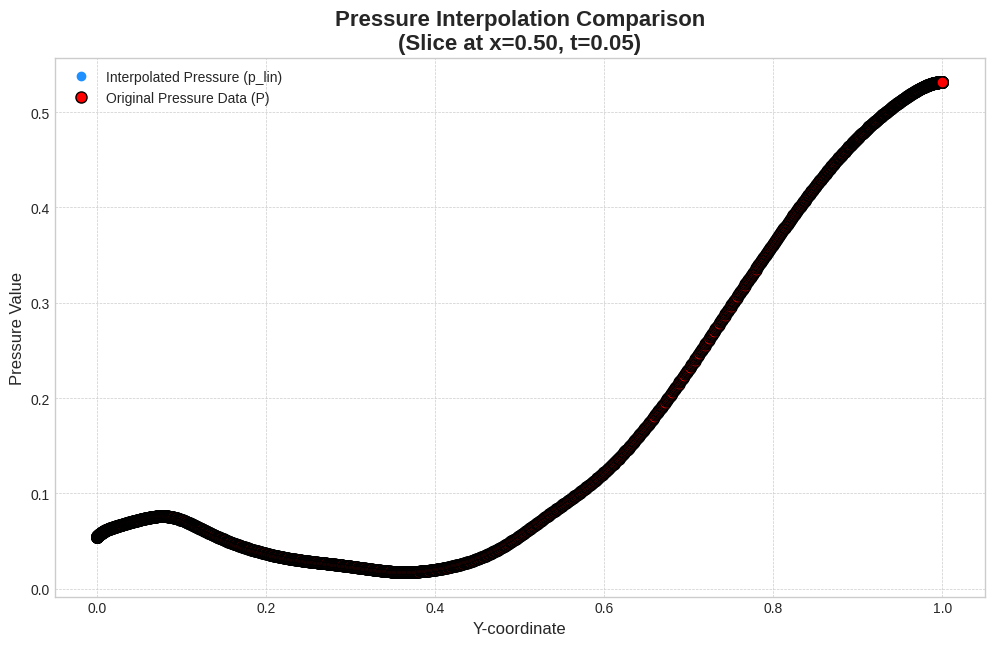

In [7]:
import matplotlib.pyplot as plt

x_index_to_plot = 512
t_index_to_plot = 100

original_pressure_slice = P[x_index_to_plot, :, t_index_to_plot]
interpolated_pressure_slice = p_lin[x_index_to_plot, :, t_index_to_plot]

# Create the plot
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 7))

# Plot the smooth, interpolated line
ax.plot(ys, interpolated_pressure_slice, 'o', label=f'Interpolated Pressure (p_lin)', color='dodgerblue', zorder=1)

# Plot the original data points on top
ax.plot(y, original_pressure_slice, 'o', label=f'Original Pressure Data (P)', color='red', markersize=8, markeredgecolor='black', zorder=2)

# Add labels and a title for clarity
ax.set_title(f'Pressure Interpolation Comparison\n(Slice at x={x[x_index_to_plot]:.2f}, t={t[t_index_to_plot]:.2f})', fontsize=16, fontweight='bold')
ax.set_xlabel('Y-coordinate', fontsize=12)
ax.set_ylabel('Pressure Value', fontsize=12)
ax.legend(fontsize=10)
ax.grid(True, which='both', linestyle='--', linewidth=0.5)

# In Jupyter, this plot will display in the cell's output
plt.show()




Calculating Continuity Residual (Divergence)...
Raw Divergence - Mean: 5.239622e+02, Max: 3.946891e+03
Raw Divergence - RMS:  6.987062e+02


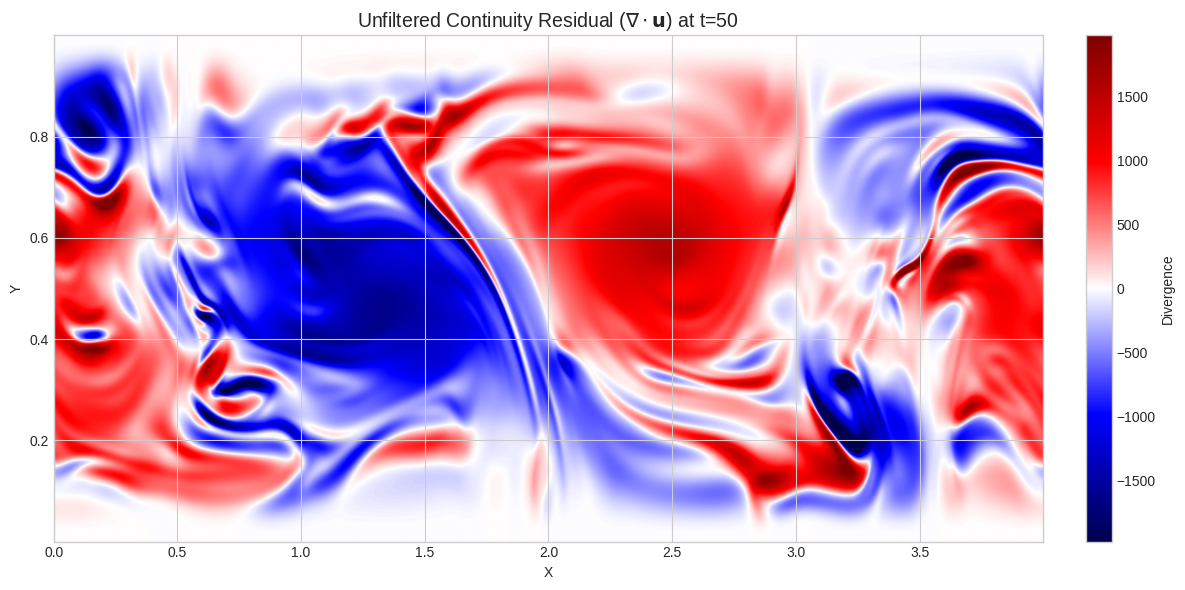

In [8]:
import numpy as np
import matplotlib.pyplot as plt

print("Calculating Continuity Residual (Divergence)...")

t_idx = 50
cmap = 'seismic'

# --- 1. Raw (Unfiltered) Divergence ---
# U, V, x, y are original loaded arrays
dx_raw = float(x[1] - x[0])
dy_raw = float(y[1] - y[0])

U_raw_t = U[:, :, t_idx]
V_raw_t = V[:, :, t_idx]

du_dx_raw = np.gradient(U_raw_t, dx_raw, axis=0)
dv_dy_raw = np.gradient(V_raw_t, dy_raw, axis=1)
div_raw = du_dx_raw + dv_dy_raw

# --- 2. Diagnostics ---
rms_div_raw = np.sqrt(np.mean(np.square(div_raw)))

print(f"Raw Divergence - Mean: {np.mean(np.abs(div_raw)):.6e}, Max: {np.max(np.abs(div_raw)):.6e}")
print(f"Raw Divergence - RMS:  {rms_div_raw:.6e}")

# --- 3. Plotting ---
extent_raw = [x[0], x[-1], y[0], y[-1]]

fig, ax = plt.subplots(figsize=(12, 6))

# Set dynamic limits to show structure rather than noise outliers
v_limit_raw = np.max(np.abs(div_raw)) * 0.5 

im = ax.imshow(
    div_raw.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_raw,
    aspect='auto',
    vmin=-v_limit_raw,
    vmax=v_limit_raw
)

ax.set_title(f"Unfiltered Continuity Residual ($\\nabla \\cdot \\mathbf{{u}}$) at t={t_idx}", fontsize=14)
ax.set_xlabel("X")
ax.set_ylabel("Y")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Divergence")

plt.tight_layout()
plt.show()

Calculating Continuity Residual (Divergence)...
Raw Divergence - Mean: 1.479579e+00, Max: 1.305803e+01
Raw Divergence - RMS:  2.132899e+00


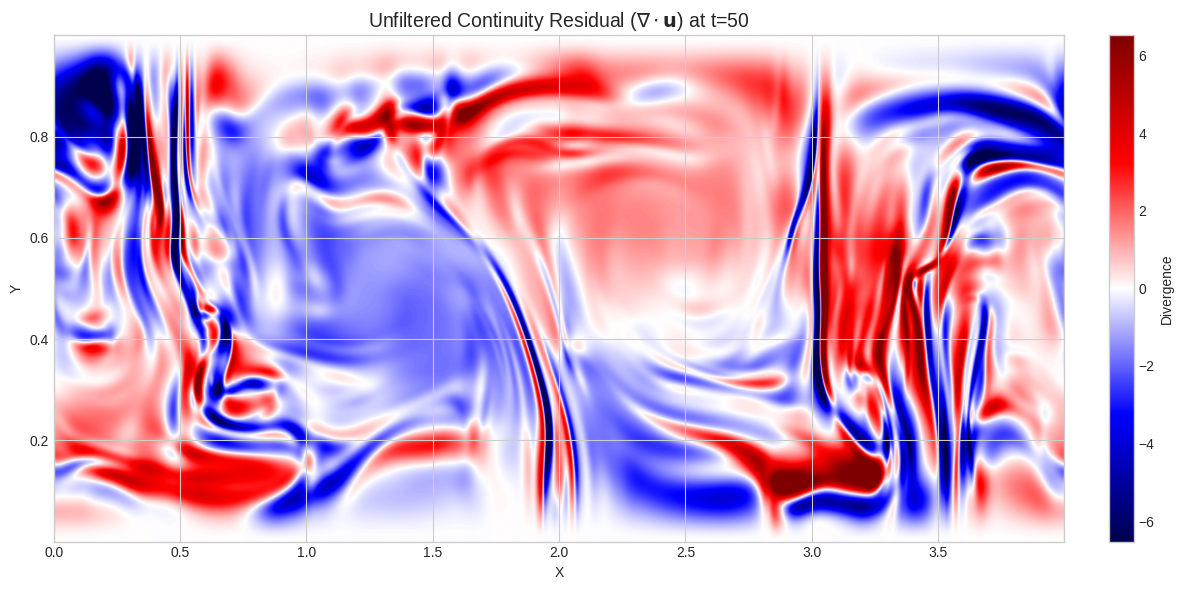

In [9]:
import numpy as np
import matplotlib.pyplot as plt

print("Calculating Continuity Residual (Divergence)...")

t_idx = 50
cmap = 'seismic'

# --- 1. Raw (Unfiltered) Divergence ---
# U, V, x, y are original loaded arrays
U_raw_t = U[:, :, t_idx]
V_raw_t = V[:, :, t_idx]

# FIX: Pass the full 1D coordinate arrays 'x' and 'y', not scalar step sizes!
du_dx_raw = np.gradient(U_raw_t, x, axis=0)
dv_dy_raw = np.gradient(V_raw_t, y, axis=1)

div_raw = du_dx_raw + dv_dy_raw

# --- 2. Diagnostics ---
rms_div_raw = np.sqrt(np.mean(np.square(div_raw)))

print(f"Raw Divergence - Mean: {np.mean(np.abs(div_raw)):.6e}, Max: {np.max(np.abs(div_raw)):.6e}")
print(f"Raw Divergence - RMS:  {rms_div_raw:.6e}")

# --- 3. Plotting ---
extent_raw = [x[0], x[-1], y[0], y[-1]]

fig, ax = plt.subplots(figsize=(12, 6))

v_limit_raw = np.max(np.abs(div_raw)) * 0.5 

im = ax.imshow(
    div_raw.T, 
    origin='lower', 
    cmap=cmap, 
    extent=extent_raw,
    aspect='auto',
    vmin=-v_limit_raw,
    vmax=v_limit_raw
)

ax.set_title(f"Unfiltered Continuity Residual ($\\nabla \\cdot \\mathbf{{u}}$) at t={t_idx}", fontsize=14)
ax.set_xlabel("X")
ax.set_ylabel("Y")
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Divergence")

plt.tight_layout()
plt.show()

In [10]:
del(U)
del(V)
del(P)
del(B)
print(v_lin.shape)
v_lin=v_lin[5:-5,5:-5,:]
u_lin=u_lin[5:-5,5:-5,:]
b_lin=b_lin[5:-5,5:-5,:]
p_lin=p_lin[5:-5,5:-5,:]
w_lin=w_lin[5:-5,5:-5,:]
print(v_lin.shape)


print(w_lin)

(4096, 1536, 101)
(4086, 1526, 101)
[[[-0.57974666 -0.57967076 -0.57959487 ... -0.57237048 -0.57229587
   -0.57222127]
  [-0.67768589 -0.67759646 -0.67750705 ... -0.66899949 -0.66891167
   -0.66882387]
  [-0.76642157 -0.76631948 -0.76621741 ... -0.75651091 -0.75641078
   -0.75631067]
  ...
  [ 0.53016546  0.53005024  0.52993503 ...  0.51896586  0.51885257
    0.5187393 ]
  [ 0.45549808  0.45539895  0.45529983 ...  0.44586162  0.44576414
    0.44566667]
  [ 0.38033972  0.38025684  0.38017398 ...  0.37228337  0.37220186
    0.37212037]]

 [[-0.57800651 -0.57793121 -0.57785591 ... -0.5706899  -0.57061591
   -0.57054193]
  [-0.67558558 -0.6754969  -0.67540824 ... -0.66697381 -0.66688677
   -0.66679975]
  [-0.7639567  -0.76385552 -0.76375436 ... -0.75413718 -0.75403799
   -0.75393882]
  ...
  [ 0.54505682  0.54493816  0.54481952 ...  0.53350866  0.53339168
    0.53327472]
  [ 0.46831392  0.46821186  0.46810981 ...  0.45837987  0.45827924
    0.45817862]
  [ 0.39105611  0.3909708   0.3908855

In [11]:
print(w_lin)

[[[-0.57974666 -0.57967076 -0.57959487 ... -0.57237048 -0.57229587
   -0.57222127]
  [-0.67768589 -0.67759646 -0.67750705 ... -0.66899949 -0.66891167
   -0.66882387]
  [-0.76642157 -0.76631948 -0.76621741 ... -0.75651091 -0.75641078
   -0.75631067]
  ...
  [ 0.53016546  0.53005024  0.52993503 ...  0.51896586  0.51885257
    0.5187393 ]
  [ 0.45549808  0.45539895  0.45529983 ...  0.44586162  0.44576414
    0.44566667]
  [ 0.38033972  0.38025684  0.38017398 ...  0.37228337  0.37220186
    0.37212037]]

 [[-0.57800651 -0.57793121 -0.57785591 ... -0.5706899  -0.57061591
   -0.57054193]
  [-0.67558558 -0.6754969  -0.67540824 ... -0.66697381 -0.66688677
   -0.66679975]
  [-0.7639567  -0.76385552 -0.76375436 ... -0.75413718 -0.75403799
   -0.75393882]
  ...
  [ 0.54505682  0.54493816  0.54481952 ...  0.53350866  0.53339168
    0.53327472]
  [ 0.46831392  0.46821186  0.46810981 ...  0.45837987  0.45827924
    0.45817862]
  [ 0.39105611  0.3909708   0.3908855  ...  0.38275261  0.38266849
    0.

In [12]:
#also u sure about ur dt? could it be wrongly input into spider#%%prun # profiling
#print(P.shape)
uobs = Observable(string='u', rank=1)
pobs = Observable(string='p', rank=0)
bobs = Observable(string='b', rank=0) #?
zobs = Observable(string='z̄', rank=1)
wobs = Observable(string='w', rank=0)
observables = [uobs, bobs, pobs, zobs, wobs]#bobszobs

u = np.concatenate([v_lin[:, :, :, np.newaxis], u_lin[:, :, :, np.newaxis]], axis=3)
z = np.full(b_lin.shape, 1)
x = np.full(b_lin.shape, 0)
unit_vect = np.concatenate([x[:, :, :, np.newaxis], z[:, :, :, np.newaxis]], axis=3)
data_dict = {'u' : u, 'b' : b_lin, 'p' : p_lin, 'z̄' : unit_vect, 'w' : w_lin}
print(u.shape)
# fix random seed
np.random.seed(1)

world_size = np.array(p_lin.shape)
pad = 0

# fix random seed
np.random.seed(1)

dxs = [dx, dy, dt]

# initial setup of dataset
srd = SRDataset(world_size=world_size, data_dict=data_dict, observables=observables, dxs=dxs, 
                irreps=SRDataset.all_rank2_irreps())
                #irreps=(0, 1, 2))

# initialize libraries, domains, and weights
#srd.make_libraries(max_complexity=4, max_observables=3)
srd.make_libraries(max_complexity=3)
for irrep in srd.irreps:
    print(irrep, ":", len(srd.libs[irrep].terms))

import os
 
# Logical cores (including hyperthreading)
num_cores = os.cpu_count()
print(f"Logical CPU cores available: {num_cores}")
Ndomainz = len(srd.libs[srd.irreps[1]].terms)*10
num_processorz = num_cores - 4
Ndomainz_rounded = num_processorz * round(Ndomainz / num_processorz)
print(len(srd.libs[srd.irreps[1]].terms))
print(num_processorz)
print(Ndomainz_rounded)
dom_width = 64 #scale for res
dom_time = 40*200//236 #previously 20 (without interpolation)
pad = 0
srd.make_domains(ndomains=Ndomainz_rounded, domain_size=[dom_width, dom_width, dom_time], pad=pad)
srd.make_weights(m=16, qmax=0)
srd.set_LT_scale(L=dx*dom_width, T=dt*dom_time) # note that this line must go before make_library_matrices
srd.make_library_matrices(debug=False, parallel=True, num_processors=num_processorz)  # or whatever number of cores you want
'''
dom_width = 64 #previously 64 - smaller world size -> smaller domain??
dom_time = 20 #previously 20 (without interpolation)
print(len(srd.libs[srd.irreps[3]].terms))
srd.make_domains(ndomains=730, domain_size=[dom_width, dom_width, dom_time], pad=pad)
#srd.make_domains(ndomains=10, domain_size=[dom_width, dom_width, dom_time], pad=pad)
srd.make_weights(m=12, qmax=0)


print(Lt)
L = dom_width
T = dom_time
#print(NLt)
print(L, T)

srd.set_LT_scale(L, T) #T=1 # note that this line must go before make_library_matrices
srd.make_library_matrices(debug=False)'''

(4086, 1526, 101, 2)
Rank 0 : 69
Rank 1 : 73
Antisymmetric rank 2 : 24
Symmetric trace-free rank 2 : 35
Logical CPU cores available: 128
73
124
744


'\ndom_width = 64 #previously 64 - smaller world size -> smaller domain??\ndom_time = 20 #previously 20 (without interpolation)\nprint(len(srd.libs[srd.irreps[3]].terms))\nsrd.make_domains(ndomains=730, domain_size=[dom_width, dom_width, dom_time], pad=pad)\n#srd.make_domains(ndomains=10, domain_size=[dom_width, dom_width, dom_time], pad=pad)\nsrd.make_weights(m=12, qmax=0)\n\n\nprint(Lt)\nL = dom_width\nT = dom_time\n#print(NLt)\nprint(L, T)\n\nsrd.set_LT_scale(L, T) #T=1 # note that this line must go before make_library_matrices\nsrd.make_library_matrices(debug=False)'

In [ ]:
'''import numpy as np
import matplotlib.pyplot as plt
import os
import imageio.v2 as imageio

# === Inputs ===
dt = 1e-2
save_folder = "u_term_frames"
make_gif = True

# Create output folder
os.makedirs(save_folder, exist_ok=True)

# Transpose u and w to (t, x, y[, ...])
u_plot = np.transpose(u, (2, 0, 1, 3))  # from (Nx, Ny, Nt, 2) -> (Nt, Nx, Ny, 2)
w_plot = np.transpose(w_lin, (2, 0, 1))     # from (Nx, Ny, Nt) -> (Nt, Nx, Ny)
n_iter = u_plot.shape[0]
#print(u_plot.shape)
# === 1. Time derivative du/dt ===
du_dt = np.zeros_like(u_plot)
du_dt[1:-1] = (u_plot[2:] - u_plot[:-2]) / (2 * dt)
du_dt[0] = (u_plot[1] - u_plot[0]) / dt
du_dt[-1] = (u_plot[-1] - u_plot[-2]) / dt

# === 2. Convective term u_beta * ∂_beta u_alpha ===
def compute_convective_term(u_t):
    uy, ux = np.gradient(u_t[..., 0], axis=(0, 1))  # ∂y u_x, ∂x u_x
    vy, vx = np.gradient(u_t[..., 1], axis=(0, 1))  # ∂y u_y, ∂x u_y

    u_x = u_t[..., 0]
    u_y = u_t[..., 1]

    adv_x = u_x * ux + u_y * uy
    adv_y = u_x * vx + u_y * vy

    return np.stack([adv_x, adv_y], axis=-1)

u_adv = np.array([compute_convective_term(u_t) for u_t in u_plot])

# === 3. Plot frames ===
filenames = []

for i in range(n_iter):
    fig, axs = plt.subplots(1, 3, figsize=(15, 4))
    
    # Compute norms
    #print(i)
    norm_dt = np.linalg.norm(du_dt[i], axis=-1)
    norm_adv = np.linalg.norm(u_adv[i], axis=-1)
    w_i = w_plot[i]

    # Plot ∂t u
    im0 = axs[0].imshow(norm_dt.T, cmap='viridis', origin='lower')
    axs[0].set_title(rf"$\partial_t u$ at $t = {i * dt:.2f}$")
    plt.colorbar(im0, ax=axs[0], fraction=0.046, pad=0.04)
    
    # Plot uβ ∂β uα
    im1 = axs[1].imshow(norm_adv.T, cmap='plasma', origin='lower')
    axs[1].set_title(r"$u_\beta \partial_\beta u_\alpha$")
    plt.colorbar(im1, ax=axs[1], fraction=0.046, pad=0.04)
    
    # Plot scalar field w
    im2 = axs[2].imshow(w_i.T, cmap='coolwarm', origin='lower')
    axs[2].set_title(r"$w$ scalar field")
    plt.colorbar(im2, ax=axs[2], fraction=0.046, pad=0.04)

    for ax in axs:
        ax.axis('off')

    filename = os.path.join(save_folder, f"frame_{i:03d}.png")
    filenames.append(filename)
    plt.tight_layout()
    plt.savefig(filename)
    plt.close()

# === 4. Optional GIF ===
if make_gif:
    gif_path = os.path.join(save_folder, "u_terms_with_w.gif")
    with imageio.get_writer(gif_path, mode='I', duration=0.05) as writer:
        for filename in filenames:
            image = imageio.imread(filename)
            writer.append_data(image)
    print(f"GIF saved to {gif_path}")
else:
    print(f"{n_iter} frames saved to '{save_folder}'")'''

In [19]:
from commons_utils import *

lib1 = srd.libs[srd.irreps[1]]
for match in regex_find(lib1.terms, r'∂t u_α'):
    print(match)
dtu = lib1.Q[:, match[0]]

for match in regex_find(lib1.terms, r'u_β · ∂β u_α'):
    print(match)
adv = lib1.Q[:, match[0]]

for match in regex_find(lib1.terms, r'∂α p'):
    print(match)
dp = lib1.Q[:, match[0]]

for match in regex_find(lib1.terms, r'∂β² u_α'):
    print(match)
viscosity = 1e-3*lib1.Q[:, match[0]] #0.1

print(np.linalg.norm(dtu), np.linalg.norm(adv), np.linalg.norm(dp), np.linalg.norm(dtu+dp+adv-viscosity), 
      np.linalg.norm(dp-viscosity), np.linalg.norm(dtu+adv))

(54, ∂t u_α)
(40, u_β · ∂β u_α)
(29, ∂α p)
(53, ∂β² u_α)
648.1862833915609 37002.63898251926 36315.938041324654 25925.25113341325 36653.80587141128 36676.717805336826


In [20]:
lib0 = srd.libs[srd.irreps[0]]
for match in regex_find(lib0.terms, r'∂α u_α'):
    print(match)
div = lib0.Q[:, match[0]]

print(np.linalg.norm(div))

(51, ∂α u_α)
11.408007032929126


In [21]:
'''from commons_identify_models import *
import copy
#Threshold: 1e-06, Initializer: combinatorial, Residual: matrix_relative, Threshold Type: information
libs = srd.libs

reg_opts_list = []
for irrep in srd.irreps:
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold
    scaler = Scaler(sub_inds=None, char_sizes=libs[irrep].col_weights, row_norms=None)
    init = Initializer(method='combinatorial', start_k=2)
    #init = Initializer(method='combinatorial', start_k=9999)
    #init = Initializer(method='power', start_k=10)
    #res = Residual(residual_type='fixed_column', anchor_col=0)
    res = Residual(residual_type='matrix_relative')
    
    iterator = ModelIterator(max_k=10, backward_forward=True, max_passes=10)
    thres = Threshold(threshold_type='information', gamma=8, delta=1e-6, n_terms=None) #gamma-delta matter a lot
    #thres = Threshold(threshold_type='information', ic=AIC)
    #thres = Threshold(threshold_type='jump', gamma=1.5, n_terms=3)
    
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,
            'model_iterator': iterator, 'threshold': thres}
    opts['verbose'] = False
    opts['inhomog'] = False
    opts['inhomog_col'] = None
    reg_opts_list.append(opts)

eqs, lambdas, reg_results, derived_eqs, excluded_terms = interleave_identify([libs[i] for i in srd.irreps], 
reg_opts_list, threshold=1e-6, experimental=True) #threshold matters
#, max_equations=10)
print(derived_eqs)
print([reg_result.all_lambdas for reg_result in reg_results])'''

"from commons_identify_models import *\nimport copy\n#Threshold: 1e-06, Initializer: combinatorial, Residual: matrix_relative, Threshold Type: information\nlibs = srd.libs\n\nreg_opts_list = []\nfor irrep in srd.irreps:\n    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold\n    scaler = Scaler(sub_inds=None, char_sizes=libs[irrep].col_weights, row_norms=None)\n    init = Initializer(method='combinatorial', start_k=2)\n    #init = Initializer(method='combinatorial', start_k=9999)\n    #init = Initializer(method='power', start_k=10)\n    #res = Residual(residual_type='fixed_column', anchor_col=0)\n    res = Residual(residual_type='matrix_relative')\n\n    iterator = ModelIterator(max_k=10, backward_forward=True, max_passes=10)\n    thres = Threshold(threshold_type='information', gamma=8, delta=1e-6, n_terms=None) #gamma-delta matter a lot\n    #thres = Threshold(threshold_type='information', ic=AIC)\n    #thres = Threshold(threshold_type='jump

In [22]:
'''from commons_identify_models import *
import copy
 
libs = srd.libs
 
# Parameter ranges for different aspects of the regression process
threshold_values = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9]
initializer_methods = ['combinatorial'] #, 'power'] 
residual_types = ['matrix_relative'] #, 'dominant_balance']
threshold_types = ['information']  #, 'jump'] # Added 'information' type
 
# Iterate through all combinations
for mk in range(5, 40):
    print("###############################################################k = " + str(mk) + "########################################")
    for threshold_loop in threshold_values:
        for init_method in initializer_methods:
            for res_type in residual_types:
                for thres_type in threshold_types:
                    print("-----------------------------------------------------------")
                    print(f"Threshold: {threshold_loop}, Initializer: {init_method}, Residual: {res_type}, Threshold Type: {thres_type}")
                    reg_opts_list = []
                    for irrep in srd.irreps:
                        scaler = Scaler(sub_inds=None, char_sizes=libs[irrep].col_weights, row_norms=None, unit_rows=True, train_fraction=0.75)
                        init = Initializer(method=init_method, start_k=mk)
                        if res_type == "dominant_balance":
                            res = Residual(residual_type='dominant_balance')
                        else:
                            res = Residual(residual_type='matrix_relative')
     
                        iterator = ModelIterator(max_k=mk, backward_forward=False, max_passes=30)
                        if thres_type == "jump":
                            thres = Threshold(threshold_type='jump', gamma=2, delta=1e-8)
                        else:  # 'information'
                            thres = Threshold(threshold_type='information', ic=AIC)
     
                        opts = {
                            'scaler': scaler,
                            'initializer': init,
                            'residual': res,
                            'model_iterator': iterator,
                            'threshold': thres,
                            'verbose': False,
                            'inhomog': False,
                            'inhomog_col': None
                        }
                        reg_opts_list.append(opts)
                    try:
                        eqs, lambdas, reg_results, derived_eqs, excluded_terms = interleave_identify(
                            [libs[i] for i in srd.irreps], reg_opts_list, threshold=threshold_loop, experimental=True)
                    except TypeError as e:
                        print(f"Encountered an error: {e}")'''

'from commons_identify_models import *\nimport copy\n\nlibs = srd.libs\n\n# Parameter ranges for different aspects of the regression process\nthreshold_values = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9]\ninitializer_methods = [\'combinatorial\'] #, \'power\'] \nresidual_types = [\'matrix_relative\'] #, \'dominant_balance\']\nthreshold_types = [\'information\']  #, \'jump\'] # Added \'information\' type\n\n# Iterate through all combinations\nfor mk in range(5, 40):\n    print("###############################################################k = " + str(mk) + "########################################")\n    for threshold_loop in threshold_values:\n        for init_method in initializer_methods:\n            for res_type in residual_types:\n                for thres_type in threshold_types:\n                    print("-----------------------------------------------------------")\n                    print(f"Threshold: {threshold_loop}, Initializer: {init_method}, Residual: {res_type}

In [23]:
'''from commons_identify_models import *
import copy
 
libs = srd.libs
 
# Parameter ranges for different aspects of the regression process
threshold_values = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9]
initializer_methods = ['combinatorial'] #  'power', 
residual_types = ['matrix_relative']
threshold_types = ['information'] # Added 'information' type , 'jump'
 
# Iterate through all combinations
for mk in range(5, 40):
    print("###############################################################k = " + str(mk) + "########################################")
    for threshold_loop in threshold_values:
        for init_method in initializer_methods:
            for res_type in residual_types:
                for thres_type in threshold_types:
                    print("-----------------------------------------------------------")
                    print(f"Threshold: {threshold_loop}, Initializer: {init_method}, Residual: {res_type}, Threshold Type: {thres_type}")
                    reg_opts_list = []
                    for irrep in srd.irreps:
                        scaler = Scaler(sub_inds=None, char_sizes=libs[irrep].col_weights, row_norms=None, unit_rows=True, train_fraction=0.75)
                        init = Initializer(method=init_method, start_k=mk)
                        if res_type == "dominant_balance":
                            res = Residual(residual_type='dominant_balance')
                        else:
                            res = Residual(residual_type='matrix_relative')
     
                        iterator = ModelIterator(max_k=mk, backward_forward=False, max_passes=30)
                        if thres_type == "jump":
                            thres = Threshold(threshold_type='jump', gamma=2, delta=1e-6)
                        else:  # 'information'
                            thres = Threshold(threshold_type='information', ic=AIC)
     
                        opts = {
                            'scaler': scaler,
                            'initializer': init,
                            'residual': res,
                            'model_iterator': iterator,
                            'threshold': thres,
                            'verbose': False,
                            'inhomog': False,
                            'inhomog_col': None
                        }
                        reg_opts_list.append(opts)
                    try:
                        eqs, lambdas, reg_results, derived_eqs, excluded_terms = interleave_identify(
                            [libs[i] for i in srd.irreps], reg_opts_list, threshold=threshold_loop, experimental=True)
                    except TypeError as e:
                        print(f"Encountered an error: {e}")'''

'from commons_identify_models import *\nimport copy\n\nlibs = srd.libs\n\n# Parameter ranges for different aspects of the regression process\nthreshold_values = [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8, 1e-9]\ninitializer_methods = [\'combinatorial\'] #  \'power\', \nresidual_types = [\'matrix_relative\']\nthreshold_types = [\'information\'] # Added \'information\' type , \'jump\'\n\n# Iterate through all combinations\nfor mk in range(5, 40):\n    print("###############################################################k = " + str(mk) + "########################################")\n    for threshold_loop in threshold_values:\n        for init_method in initializer_methods:\n            for res_type in residual_types:\n                for thres_type in threshold_types:\n                    print("-----------------------------------------------------------")\n                    print(f"Threshold: {threshold_loop}, Initializer: {init_method}, Residual: {res_type}, Threshold Type: {thres_typ

In [ ]:
''' Threshold: 0.0001, Initializer: power, Residual: matrix_relative, Threshold Type: information
not picking up above 1024
sze 1024 = train res 9.04e-05, test res 7.16e-05
sze 512  = train res 9.33e-05, test res 7.39e-05
sze 256 = train res 9.40e-05, test res 7.45e-05
sze 128 = train res 9.42e-05, test res 7.46e-05
sze 64 = train res 9.43e-05, test res 7.47e-05
sze 32 = train res 9.43e-05, test res 7.47e-05

????Identified model: 0.355 · ∂α b · u_α + ∂t b = 0 (order 3, train res 5.89e-06, test res 1.29e-05)
1.1 e-6 Identified model: -0.252 · b · ∂α u_α + 0.00581 · ∂α b · u_α + 0.000173 · ∂α² b + 0.00556 · ∂t b + ∂α u_α = 0 (order 3, train res 1.35e-07, test res 2.21e-07)
Identified model: -0.252 · b · ∂α u_α + 0.00581 · ∂α b · u_α + 0.000173 · ∂α² b + 0.00556 · ∂t b + ∂α u_α = 0 (order 3, train res 1.35e-07, test res 2.21e-07)
Identified model: -0.252 · b · ∂α u_α + 0.00581 · ∂α b · u_α + 0.000173 · ∂α² b + 0.00556 · ∂t b + ∂α u_α = 0 (order 3, train res 1.35e-07, test res 2.21e-07)
Identified model: -0.252 · b · ∂α u_α + 0.00585 · ∂α b · u_α + 0.000168 · ∂α² b + 0.00551 · ∂t b + ∂α u_α = 0 (order 3, train res 1.42e-07, test res 2.34e-07)
Identified model: -0.252 · b · ∂α u_α + 0.00585 · ∂α b · u_α + 0.000168 · ∂α² b + 0.00551 · ∂t b + ∂α u_α = 0 (order 3, train res 1.42e-07, test res 2.34e-07)
Identified model: 0.00131 · b · ∂t b + -0.252 · b · ∂α u_α + 0.00485 · ∂α b · u_α + 0.000182 · ∂α² b + ∂α u_α = 0 (order 3, train res 1.53e-07, test res 2.98e-07)
Identified model: -0.252 · b · ∂α u_α + 0.00476 · ∂α b · u_α + 0.000179 · ∂α² b + 0.00498 · ∂t b + ∂α u_α = 0 (order 3, train res 1.51e-07, test res 2.88e-07)

'''

In [13]:
lib3 = srd.libs[srd.irreps[0]]
for idx, term in enumerate(lib3.terms):
    if str(term) == "∂α u_α":#"∂t b": #"u_β · ∂β u_α"
        print(f"Found at index {idx}: {term}") 
print(lib3)

Found at index 51: ∂α u_α
LibraryData(terms=[b, b · b, b · b · b, b · b · p, b · b · w, b · ∂t b, b · p, b · p · p, b · p · w, b · ∂t p, b · u_α · u_α, b · u_α · z̄_α, b · ∂α u_α, b · w, b · w · w, b · ∂t w, b · z̄_α · z̄_α, b · ∂α z̄_α, ∂α b · u_α, ∂α b · z̄_α, ∂α² b, ∂t b, ∂t b · p, ∂t b · w, ∂t² b, p, p · p, p · p · p, p · p · w, p · ∂t p, p · u_α · u_α, p · u_α · z̄_α, p · ∂α u_α, p · w, p · w · w, p · ∂t w, p · z̄_α · z̄_α, p · ∂α z̄_α, ∂α p · u_α, ∂α p · z̄_α, ∂α² p, ∂t p, ∂t p · w, ∂t² p, u_α · u_α, u_α · u_α · w, u_α · ∂t u_α, u_α · w · z̄_α, u_α · ∂α w, u_α · z̄_α, u_α · ∂t z̄_α, ∂α u_α, ∂α u_α · w, ∂t u_α · z̄_α, ∂t ∂α u_α, w, w · w, w · w · w, w · ∂t w, w · z̄_α · z̄_α, w · ∂α z̄_α, ∂α w · z̄_α, ∂α² w, ∂t w, ∂t² w, z̄_α · z̄_α, z̄_α · ∂t z̄_α, ∂α z̄_α, ∂t ∂α z̄_α], irrep=Rank 0, Q=array([[ 6.22620315e+02,  3.00661299e+02,  1.45189060e+02, ...,
         0.00000000e+00, -1.02893580e-07, -8.47032947e-22],
       [ 6.61078371e+02,  3.38950702e+02,  1.73788859e+02, ...,
         

In [25]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 21 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

Number of Terms in inhomogenous regression:  1
∂t b = 0 ; residual: 0.00026860207514148093

Number of Terms in inhomogenous regression:  2
0.03432644531724235 · ∂α b · u_α + ∂t b = 0 ; residual: 8.542254430536348e-06

Number of Terms in inhomogenous regression:  3
0.03437903396892621 · ∂α b · u_α + -3.437380935260665e-06 · ∂α² b + ∂t b = 0 ; residual: 4.9975738616337965e-08

Number of Terms in inhomogenous regression:  4
0.034378952873494684 · ∂α b · u_α + -4.5371927760149645e-07 · ∂α b · z̄_α + -3.4375892622547093e-06 · ∂α² b + ∂t b = 0 ; residual: 4.8423359499524414e-08

Number of Terms in inhomogenous regression:  5
0.03437903387148566 · ∂α b · u_α + -4.4222054068693377e-07 · ∂α b · z̄_α + -3.4375928993943088e-06 · ∂α² b + ∂t b + 9.145560681108652e-07 · u_α · z̄_α = 0 ; residual: 4.7358036665548665e-08



In [26]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[1]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 40 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

Number of Terms in inhomogenous regression:  1
u_β · ∂β u_α = 0 ; residual: 0.08026988997550967

Number of Terms in inhomogenous regression:  2
b · ∂α p + 0.5334640328800606 · u_β · ∂β u_α = 0 ; residual: 0.021382710367858233

Number of Terms in inhomogenous regression:  3
0.031999593717124304 · ∂α p + 0.03415034859660651 · u_β · ∂β u_α + ∂t u_α = 0 ; residual: 9.085358402289118e-05

Number of Terms in inhomogenous regression:  4
-0.03437045084741883 · b · z̄_α + 0.03435670472927903 · ∂α p + 0.03435202046800314 · u_β · ∂β u_α + ∂t u_α = 0 ; residual: 2.515190418595172e-06

Number of Terms in inhomogenous regression:  5
-0.03438254006625614 · b · z̄_α + 0.03438226712847641 · ∂α p + 0.0343761323578657 · u_β · ∂β u_α + -3.440638951300816e-06 · ∂β² u_α + ∂t u_α = 0 ; residual: 4.598048389874847e-08



In [27]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[1]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 11 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

Number of Terms in inhomogenous regression:  1
b · z̄_α = 0 ; residual: 0.12847319292099918

Number of Terms in inhomogenous regression:  2
2.480654572166676e-14 · b · z̄_α + b · ∂t z̄_α = 0 ; residual: 1.5115943080517813e-29

Number of Terms in inhomogenous regression:  3
2.480654572166689e-14 · b · z̄_α + b · ∂t z̄_α + 1.4536907501130081e-25 · ∂t b · z̄_α = 0 ; residual: 8.716101585826122e-32

Number of Terms in inhomogenous regression:  4
2.4806545721666876e-14 · b · z̄_α + b · ∂t z̄_α + 1.453490446801451e-25 · ∂t b · z̄_α + 3.217822866636646e-30 · u_α · ∂t w = 0 ; residual: 7.958345238996143e-32

Number of Terms in inhomogenous regression:  5
2.4806545721666876e-14 · b · z̄_α + b · ∂t z̄_α + 1.453490446801451e-25 · ∂t b · z̄_α + 3.217822866636646e-30 · u_α · ∂t w = 0 ; residual: 7.958345238996143e-32



In [28]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[1]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 11 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

Number of Terms in inhomogenous regression:  1
b · z̄_α = 0 ; residual: 0.12847319292099918

Number of Terms in inhomogenous regression:  2
2.480654572166676e-14 · b · z̄_α + b · ∂t z̄_α = 0 ; residual: 1.5115943080517813e-29

Number of Terms in inhomogenous regression:  3
2.480654572166689e-14 · b · z̄_α + b · ∂t z̄_α + 1.4536907501130081e-25 · ∂t b · z̄_α = 0 ; residual: 8.716101585826122e-32

Number of Terms in inhomogenous regression:  4
2.4806545721666876e-14 · b · z̄_α + b · ∂t z̄_α + 1.453490446801451e-25 · ∂t b · z̄_α + 3.217822866636646e-30 · u_α · ∂t w = 0 ; residual: 7.958345238996143e-32

Number of Terms in inhomogenous regression:  5
2.4806545721666876e-14 · b · z̄_α + b · ∂t z̄_α + 1.453490446801451e-25 · ∂t b · z̄_α + 3.217822866636646e-30 · u_α · ∂t w = 0 ; residual: 7.958345238996143e-32



In [42]:
from commons_identify_models import *

import copy
 
libs = srd.libs

lib3 = libs[srd.irreps[0]]
 
for aaaa in range(1,6):

    max_kk = 5

    print("Number of Terms in inhomogenous regression: ", aaaa)

    reg_opts_list = []
 
    # for regression we now need to construct a Scaler, Initializer, ModelIterator, and Threshold

    scaler = Scaler(sub_inds=None, char_sizes=lib3.col_weights, row_norms=None, train_fraction=1, unit_rows=True)

    #init = Initializer(method='combinatorial', start_k=2)

    #init = Initializer(method='combinatorial', start_k=9999)

    init = Initializer(method='combinatorial', start_k=max_kk)

    #res = Residual(residual_type='fixed_column', anchor_col=0)

    #res = Residual(residual_type='dominant_balance')

    res = Residual(residual_type='matrix_relative')
 
    iterator = ModelIterator(max_k=max_kk, backward_forward=True, max_passes=20)

    thres = Threshold(threshold_type='jump', gamma=1.5, delta=1e-6, n_terms=aaaa)

    #thres = Threshold(threshold_type='information', ic=AIC)
 
    opts = {'scaler': scaler, 'initializer': init, 'residual': res,

            'model_iterator': iterator, 'threshold': thres}

    opts['verbose'] = False

    opts['inhomog'] = True

    opts['inhomog_col'] = 51 #25
 
    reg_result = sparse_reg_bf(lib3.Q, **opts)

    zipped = [(lib3.terms[i], c) for i, c in enumerate(reg_result.xi) if c != 0]

    eqn = Equation([e[0] for e in zipped], [e[1] for e in zipped])
 
    print(eqn, "; residual:", reg_result.lambd)

    print("")
 

Number of Terms in inhomogenous regression:  1
∂α u_α = 0 ; residual: 4.67806627202192e-06

Number of Terms in inhomogenous regression:  2
b · ∂α u_α + -0.5071635251610154 · ∂α u_α = 0 ; residual: 3.2579471149026796e-07

Number of Terms in inhomogenous regression:  3
b · ∂α u_α + 0.08159025378302527 · p · ∂α u_α + -0.5128825068695219 · ∂α u_α = 0 ; residual: 3.153320975379892e-07

Number of Terms in inhomogenous regression:  4
b · ∂α u_α + -4.6906110367824974e-05 · b · w + -0.5084086311619321 · ∂α u_α + 2.411533680864373e-05 · w = 0 ; residual: 3.0516728558436874e-07

Number of Terms in inhomogenous regression:  5
b · ∂α u_α + -4.468633744458562e-05 · b · w + 0.07662810975674426 · p · ∂α u_α + -0.514160530579145 · ∂α u_α + 2.3151333448083106e-05 · w = 0 ; residual: 2.9560008953402487e-07

